**Step 1: Install and import**

In [1]:
!pip install -q xgboost shap imbalanced-learn

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, shap

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict,
                                     RandomizedSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score,
                             average_precision_score, f1_score,
                             precision_recall_curve, PrecisionRecallDisplay,
                             RocCurveDisplay)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

**Step 2: Upload and check the data**

In [2]:
from google.colab import files
uploaded = files.upload()          # choose instagram_fake_profile_v3.csv
DATA_PATH = list(uploaded.keys())[0]

df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.isna().sum().sum(), "missing values;", df.duplicated().sum(), "duplicate rows")
print(df["is_fake"].value_counts(normalize=True).round(3).to_dict())
df.head()

Saving instagram_fake_profile_v4.csv to instagram_fake_profile_v4 (1).csv
(5000, 9)
0 missing values; 0 duplicate rows
{0: 0.868, 1: 0.132}


,profile_picture,bio_length,username,followers,following,posts,account_age_days,username_changed,is_fake
0,1,50,ishaan.clark17499,854,338,710,399,2,0
1,1,72,ayaanyoung,312,297,25,761,0,0
2,1,55,aarav.gupta,102,697,327,459,1,0
3,0,39,rahul_reddy,382,553,106,427,1,0
4,1,23,dev84232,918,110,15,984,1,0


**Step 3: Build the features**

In [3]:
RAW_COLS = ["profile_picture", "bio_length", "username", "followers",
            "following", "posts", "account_age_days", "username_changed"]

FEATURES = ["profile_picture", "bio_length", "followers", "following",
            "posts", "account_age_days", "username_changed",
            "followers_following_ratio", "followers_per_day",
            "posts_per_day", "username_digits"]

def make_features(raw):
    d = raw.copy()
    d["followers_following_ratio"] = d["followers"] / (d["following"] + 1)
    d["followers_per_day"] = d["followers"] / (d["account_age_days"] + 1)
    d["posts_per_day"] = d["posts"] / (d["account_age_days"] + 1)
    d["username_digits"] = d["username"].astype(str).str.count(r"\d")
    return d[FEATURES]

X = make_features(df[RAW_COLS])
y = df["is_fake"].values
X.head()

,profile_picture,bio_length,followers,following,posts,account_age_days,username_changed,followers_following_ratio,followers_per_day,posts_per_day,username_digits
0,1,50,854,338,710,399,2,2.519174,2.135000,1.775000,5
1,1,72,312,297,25,761,0,1.046980,0.409449,0.032808,0
2,1,55,102,697,327,459,1,0.146132,0.221739,0.710870,0
3,0,39,382,553,106,427,1,0.689531,0.892523,0.247664,0
4,1,23,918,110,15,984,1,8.270270,0.931980,0.015228,5


**Step 4: Split into train and test**

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, "test:", X_test.shape,
      "| fake rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos        # imbalance weight for XGBoost


train: (4000, 11) test: (1000, 11) | fake rate train/test: 0.132 0.132


**Step 5: Compare the models**

In [5]:
log_tf = FunctionTransformer(np.log1p, feature_names_out="one-to-one")

models = {
    "Logistic Regression": Pipeline([
        ("log", log_tf), ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample",
        min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost (class weight)": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        scale_pos_weight=spw, eval_metric="logloss",
        n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost + SMOTE": ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", XGBClassifier(n_estimators=300, learning_rate=0.05,
                              max_depth=4, eval_metric="logloss",
                              n_jobs=-1, random_state=RANDOM_STATE))]),
}

scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "f1": "f1", "precision": "precision", "recall": "recall"}
rows = []
for name, model in models.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in scoring}})
comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison

,roc_auc,pr_auc,f1,precision,recall
model,,,,,
Logistic Regression,0.836,0.642,0.493,0.371,0.735
Random Forest,0.836,0.620,0.584,0.704,0.500
XGBoost (class weight),0.815,0.609,0.550,0.496,0.618
XGBoost + SMOTE,0.804,0.576,0.532,0.472,0.610


**Step 6: Tune XGBoost**

In [6]:
param_dist = {
    "n_estimators": [150, 250, 400, 600],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5, 6],
    "min_child_weight": [1, 3, 5, 10],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "gamma": [0, 0.5, 1, 2],
    "reg_lambda": [0.5, 1, 2, 5],
}
search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=spw, eval_metric="logloss",
                  n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=param_dist, n_iter=25, scoring="average_precision",
    cv=cv, random_state=RANDOM_STATE, n_jobs=1, verbose=0)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best params:", search.best_params_)
print("Best CV PR-AUC:", round(search.best_score_, 3))

Best params: {'subsample': 0.7, 'reg_lambda': 0.5, 'n_estimators': 150, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.85}
Best CV PR-AUC: 0.636


**Step 7: Choose the decision threshold**

In [7]:
oof = cross_val_predict(best_model, X_train, y_train, cv=cv,
                        method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
THRESHOLD = float(thr[np.argmax(f1s)])
print("Chosen threshold:", round(THRESHOLD, 3))

Chosen threshold: 0.684


**Step 8: Final test-set evaluation**

Test ROC-AUC: 0.821
Test PR-AUC : 0.605 (random baseline = 0.132 )
Test F1     : 0.571
              precision    recall  f1-score   support

     genuine       0.93      0.94      0.94       868
        fake       0.58      0.56      0.57       132

    accuracy                           0.89      1000
   macro avg       0.76      0.75      0.75      1000
weighted avg       0.89      0.89      0.89      1000



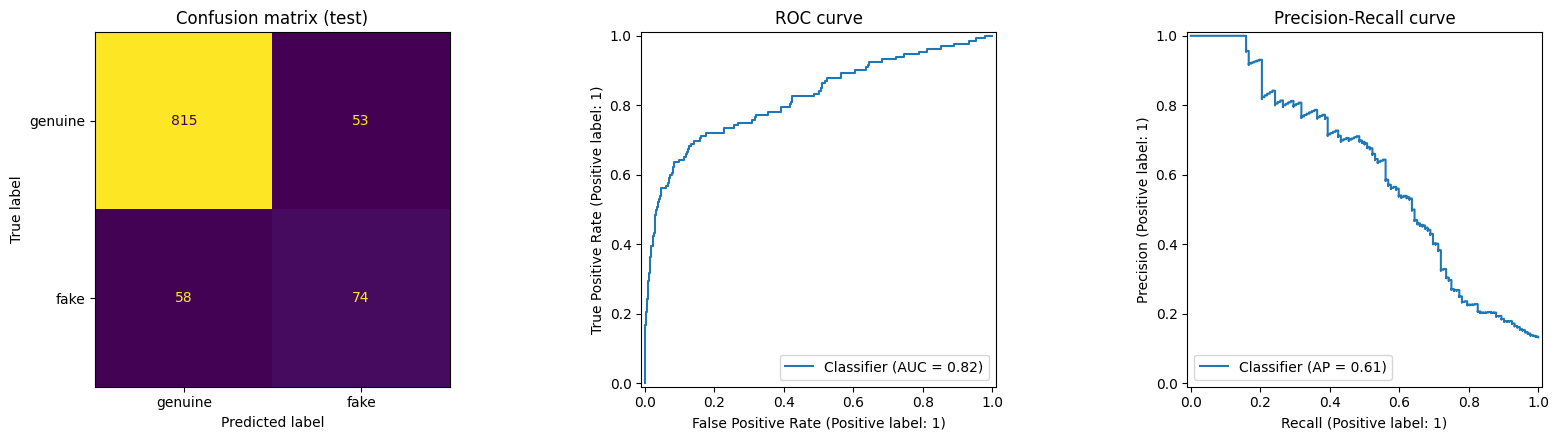

In [8]:
best_model.fit(X_train, y_train)
proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= THRESHOLD).astype(int)

print("Test ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("Test PR-AUC :", round(average_precision_score(y_test, proba), 3),
      "(random baseline =", round(y_test.mean(), 3), ")")
print("Test F1     :", round(f1_score(y_test, pred), 3))
print(classification_report(y_test, pred, target_names=["genuine", "fake"]))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["genuine", "fake"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1]); ax[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=ax[2]); ax[2].set_title("Precision-Recall curve")
plt.tight_layout(); plt.show()

**Step 9: SHAP explanations**

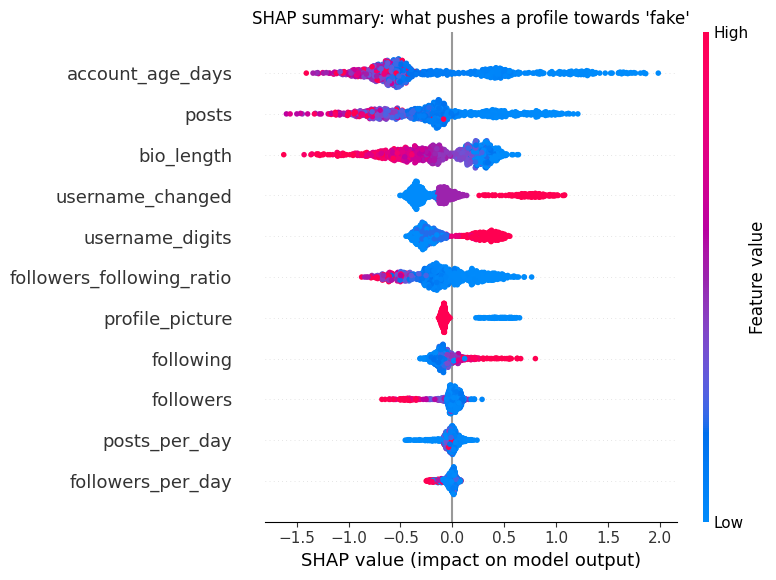

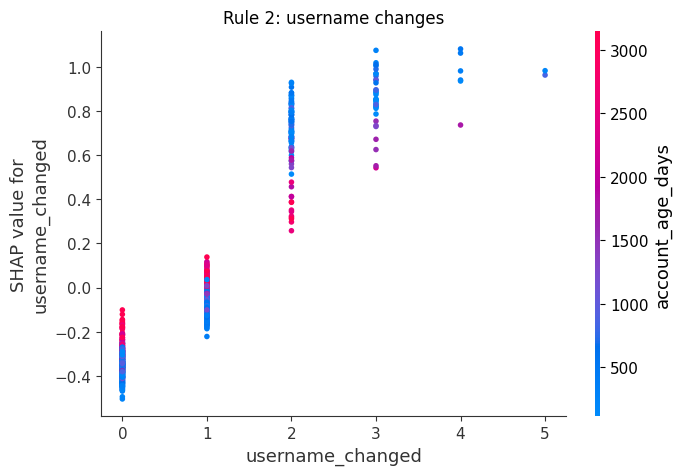

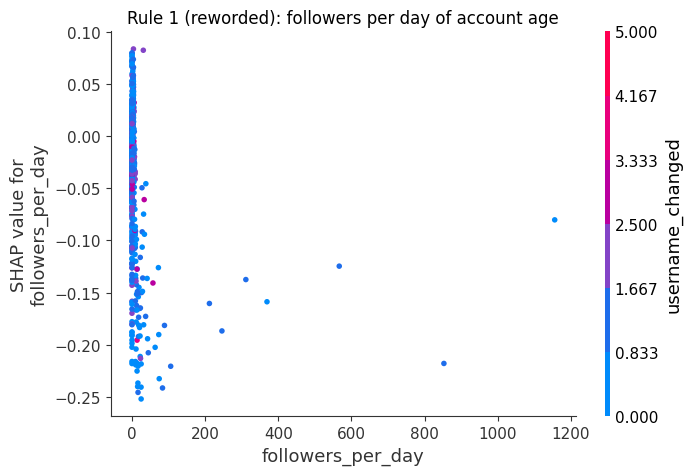

In [9]:
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP summary: what pushes a profile towards 'fake'")
plt.tight_layout(); plt.show()

shap.dependence_plot("username_changed", shap_values, X_test, show=False)
plt.title("Rule 2: username changes"); plt.show()

shap.dependence_plot("followers_per_day", shap_values, X_test, show=False)
plt.title("Rule 1 (reworded): followers per day of account age"); plt.show()

**Step 10: Save the model**

In [10]:
joblib.dump({"model": best_model, "threshold": THRESHOLD,
             "features": FEATURES, "raw_cols": RAW_COLS},
            "fake_profile_model.joblib")
files.download("fake_profile_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Step 11: Test one profile**

In [12]:
def predict_profile(profile_picture, bio_length, username, followers,
                    following, posts, account_age_days, username_changed):
    bundle = joblib.load("fake_profile_model.joblib")
    raw = pd.DataFrame([{
        "profile_picture": profile_picture, "bio_length": bio_length,
        "username": username, "followers": followers, "following": following,
        "posts": posts, "account_age_days": account_age_days,
        "username_changed": username_changed}])
    p = bundle["model"].predict_proba(make_features(raw[bundle["raw_cols"]]))[0, 1]
    return {"fake_probability": round(float(p), 3),
            "verdict": "FAKE / suspicious" if p >= bundle["threshold"] else "Genuine"}

print(predict_profile(0, 0, "user48291", 1200, 3500, 2, 20, 4))       # suspicious-looking
print(predict_profile(1, 90, "priya.sharma", 850, 600, 210, 1800, 0))  # normal-looking

{'fake_probability': 0.994, 'verdict': 'FAKE / suspicious'}
{'fake_probability': 0.097, 'verdict': 'Genuine'}
